In [1]:
import os
import json
import torch
import matplotlib.pyplot as plt


# ============================================================
# CONFIGURATION
# ============================================================

RESULTS_ROOT = "./results"

DATASETS = [
    "THEIA_E3",
    "THEIA_E5",
    "TRACE_E3",
    "TRACE_E5",
]

METHODS = [
    "flash",
    "velox",
    "orthrus",
]



PROFILE_REMOVED_NODES = {

    "THEIA_E3": {
        "1_random": 37,
        "2_random": 30,
        "3_random": 12,
    },

    "THEIA_E5": {
        "1_random": 65,
        "2_random": 18,
        "3_random": 13,
    },

    "TRACE_E3": {
        "1_random": 32,
        "2_random": 30,
        "3_random": 16,
    },

    "TRACE_E5": {
        "1_random": 68,
        "2_random": 11,
        "3_random": 5,
    },
}




# ============================================================
# METRIC CALCULATION
# ============================================================

def calculate_metrics(results_path):

    data = torch.load(
        results_path,
        map_location="cpu"
    )

    tp = set()
    fp = set()
    tn = set()
    fn = set()

    for key, item in data.items():

        y_hat = item["y_hat"]
        y_true = item["y_true"]

        if y_hat == 1:

            if y_true == 1:
                tp.add(key)
            else:
                fp.add(key)

        else:

            if y_true == 1:
                fn.add(key)
            else:
                tn.add(key)

    tp = len(tp)
    fp = len(fp)
    tn = len(tn)
    fn = len(fn)

    eps = 1e-10

    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)

    f1 = (
        2 * precision * recall /
        (precision + recall + eps)
    )

    return {
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


# ============================================================
# FIND RESULT FILE
# ============================================================

def find_result_file(dataset, method, configuration):

    path = os.path.join(
        RESULTS_ROOT,
        dataset,
        method,
        configuration,
        "results",
        "results.pth"
    )

    if os.path.exists(path):
        return path

    return None


# ============================================================
# DETERMINE CONFIGURATION
# ============================================================

def get_configurations():

    return [
        "base",
        "75",
        "50",
        "25",
        # "1_random",
        # "2_random",
        # "3_random",
    ]


# ============================================================
# GET REMOVAL PERCENTAGE
# ============================================================

def get_removal_percentage(dataset, configuration):

    # Full training set
    if configuration == "base":
        return 0.0

    # Random volume reductions
    #
    # trace_e5_75 means 75% retained
    # therefore 25% removed
    #
    # trace_e5_50 -> 50% removed
    # trace_e5_25 -> 75% removed

    elif configuration == "75":
        return 25.0

    elif configuration == "50":
        return 50.0

    elif configuration == "25":
        return 75.0

    # Dominant profile removal
    else:

        return PROFILE_REMOVED_NODES[
            dataset
        ][configuration]



# ============================================================
# COLLECT ALL RESULTS
# ============================================================

def collect_results():

    output = {}

    for dataset in DATASETS:

        output[dataset] = {}

        for method in METHODS:

            output[dataset][method] = {}

            for configuration in get_configurations():

                # Directory name
                if configuration == "base":
                    dirname = dataset.lower()
                else:
                    dirname = (
                        dataset.lower()
                        + "_"
                        + configuration
                    )

                result_path = find_result_file(
                    dataset,
                    method,
                    dirname
                )

                if result_path is None:
                    print(
                        "MISSING:",
                        dataset,
                        method,
                        dirname
                    )
                    continue
                print(result_path)
                metrics = calculate_metrics(
                    result_path
                )

                removal = get_removal_percentage(
                    dataset,
                    configuration
                )

                output[dataset][method][configuration] = {
                    "removal_percent": removal,
                    "TP": metrics["TP"],
                    "FP": metrics["FP"],
                    "TN": metrics["TN"],
                    "FN": metrics["FN"],
                    "precision": metrics["precision"],
                    "recall": metrics["recall"],
                    "f1": metrics["f1"],
                    "path": result_path,
                }

    return output


# ============================================================
# SAVE JSON
# ============================================================

results = collect_results()

with open(
    "training_volume_results.json",
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )

print(
    "\nSaved:",
    "training_volume_results.json"
)



./results\THEIA_E3\flash\theia_e3\results\results.pth
./results\THEIA_E3\flash\theia_e3_75\results\results.pth
./results\THEIA_E3\flash\theia_e3_50\results\results.pth
./results\THEIA_E3\flash\theia_e3_25\results\results.pth
./results\THEIA_E3\velox\theia_e3\results\results.pth
./results\THEIA_E3\velox\theia_e3_75\results\results.pth
./results\THEIA_E3\velox\theia_e3_50\results\results.pth
./results\THEIA_E3\velox\theia_e3_25\results\results.pth
./results\THEIA_E3\orthrus\theia_e3\results\results.pth
./results\THEIA_E3\orthrus\theia_e3_75\results\results.pth
./results\THEIA_E3\orthrus\theia_e3_50\results\results.pth
./results\THEIA_E3\orthrus\theia_e3_25\results\results.pth
./results\THEIA_E5\flash\theia_e5\results\results.pth
./results\THEIA_E5\flash\theia_e5_75\results\results.pth
./results\THEIA_E5\flash\theia_e5_50\results\results.pth
./results\THEIA_E5\flash\theia_e5_25\results\results.pth
./results\THEIA_E5\velox\theia_e5\results\results.pth
./results\THEIA_E5\velox\theia_e5_75\r

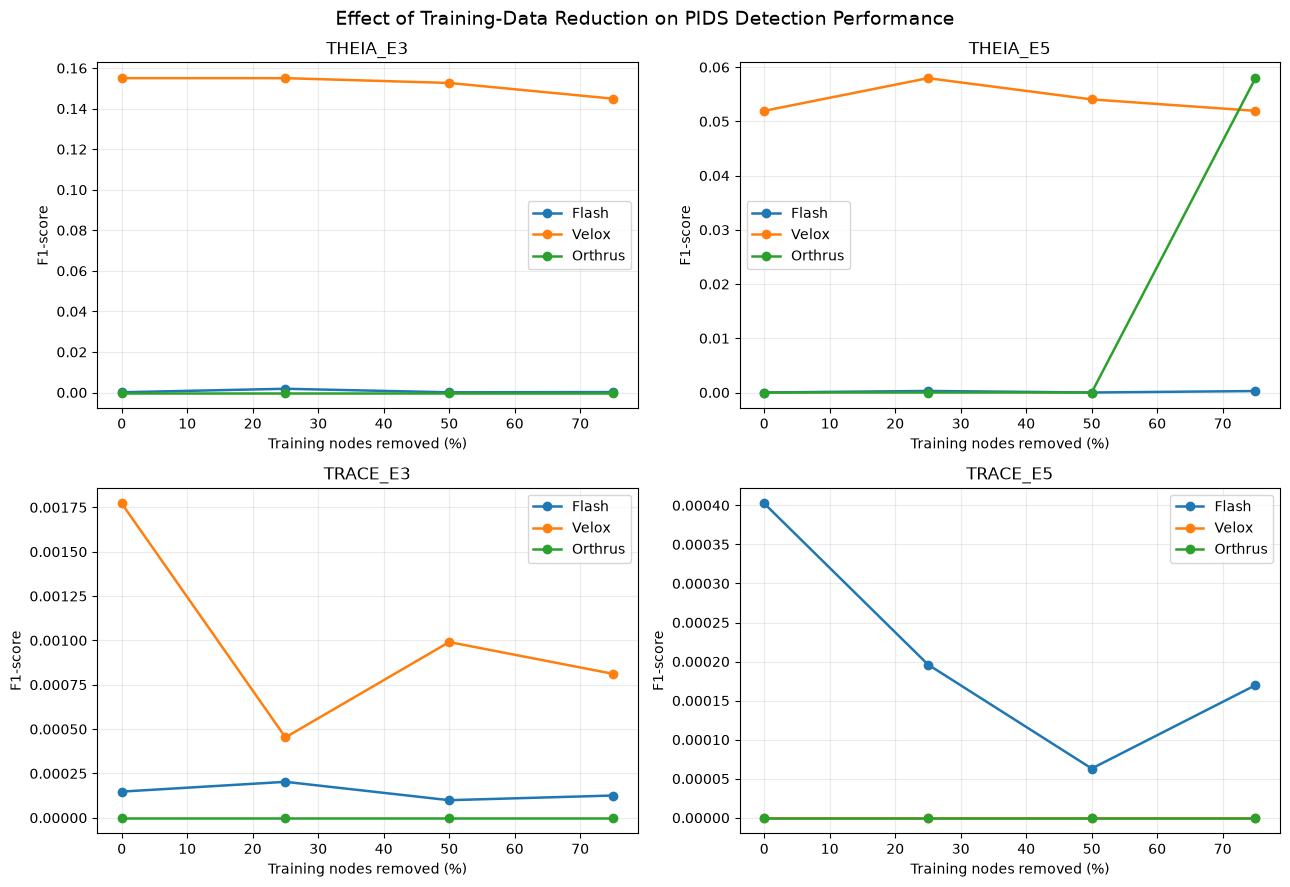

In [2]:



# ============================================================
# PLOT F1
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9),
    sharex=False,
    sharey=False
)

axes = axes.flatten()

for ax, dataset in zip(axes, DATASETS):

    for method in METHODS:

        configs = results[dataset].get(
            method,
            {}
        )

        points = []

        for config, values in configs.items():

            removal = values["removal_percent"]

            if removal is not None:

                points.append(
                    (
                        removal,
                        values["f1"],
                        config
                    )
                )

        # Sort by percentage removed
        points.sort(
            key=lambda x: x[0]
        )

        if not points:
            continue

        x = [
            p[0]
            for p in points
        ]

        y = [
            p[1]
            for p in points
        ]

        ax.plot(
            x,
            y,
            marker="o",
            linewidth=1.8,
            label=method.capitalize()
        )

    ax.set_title(dataset)

    ax.set_xlabel(
        "Training nodes removed (%)"
    )

    ax.set_ylabel(
        "F1-score"
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.legend()


fig.suptitle(
    "Effect of Training-Data Reduction on PIDS Detection Performance",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "training_volume_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()